![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 02 | Pipelines and Models

*Project 2 — Machine Learning: From Data to Predictions*

**Team:**
**Dataset:**

---

Steps 5 to 8 of the workflow: build the pipeline, compare models fairly, tune the best, and choose the threshold. Everything here uses the training set only.

> **Done when:** you have a comparison table of at least three model families on the same folds against the baseline, the best one or two tuned, and a final model chosen for reasons you can state.

The sections below are a suggested route, not a form to fill in. Add sections, drop them, reorder them — what is graded is the work, not whether you kept the scaffold.

---
## 0. Setup

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV,RandomizedSearchCV, TunedThresholdClassifierCV
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, fbeta_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from scipy.stats import loguniform, randint

---
## 1. Load and split

The same loading and the same split as notebook 01. Put the code in `src/functions.py` so both notebooks use exactly the same rows.

In [3]:
df = load_data()

X_train, X_test, y_train, y_test = split_data(df)

print(f"Train features shape: {X_train.shape}\nTest features shape: {X_test.shape}\n")
print(f"Train target mean: {y_train.mean().round(3)}\nTest target mean: {y_test.mean().round(3)}") 


Train features shape: (5634, 19)
Test features shape: (1409, 19)

Train target mean: 0.265
Test target mean: 0.265


---
## 2. The preprocessing pipeline

A `ColumnTransformer` with one branch per column type: impute, scale, encode. **Everything that learns from data goes inside**, so cross-validation refits it on every fold.

In [4]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "PaperlessBilling", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "Contract", "PaymentMethod"]

preprocessor = build_preprocessor(num_cols, cat_cols)
print(preprocessor.fit_transform(X_train).shape)

(5634, 40)


---
## 3. First model in the pipeline

One simple model at the end of the pipeline, scored with cross-validation. Is it better than the baseline, and by more than the spread across folds?

In [5]:
# Baseline model
dummy = DummyClassifier()
baseline = cross_validate(dummy, X_train, y_train, cv=CV, scoring=SCORING)
for metric in SCORING:
    print(f"{metric}: {baseline[f'test_{metric}'].mean():.3f}")

f2: 0.000
average_precision: 0.265
recall: 0.000
precision: 0.000
f1: 0.000
accuracy: 0.735


In [6]:
# Cross validation step to be used in every next step

pipe_lr = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced')),
])

res = cross_validate(pipe_lr, X_train, y_train, cv=CV, scoring=SCORING)
for model in SCORING:
    s = res[f'test_{model}']
    print(f"{model}: {s.mean():.3f} ± {s.std():.3f}  (baseline {baseline[f'test_{model}'].mean():.3f})")

f2: 0.720 ± 0.005  (baseline 0.000)
average_precision: 0.652 ± 0.030  (baseline 0.265)
recall: 0.801 ± 0.005  (baseline 0.000)
precision: 0.513 ± 0.011  (baseline 0.000)
f1: 0.625 ± 0.008  (baseline 0.000)
accuracy: 0.745 ± 0.008  (baseline 0.735)


Logistic regression reaches recall 0.801 and F1 0.625  against 0 for the baseline, far more than the spread across folds.

---
## 4. Features

New features added inside the pipeline. Keep a feature only if it improves the cross-validated score, and write down what each one changed.

In [7]:
for feats in [(),('n_addons',), ('new_customer',), ('con_serv',)]:
    pipe = Pipeline([
        ("features", FunctionTransformer(add_features, kw_args={"features": feats})),
        ("prep", build_preprocessor(num_cols + list(feats), cat_cols)),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ])
    r = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING)
    print(feats or "no new features",
          f"recall {r['test_recall'].mean():.3f} ± {r['test_recall'].std():.3f}",
          f"f1 {r['test_f1'].mean():.3f} ± {r['test_f1'].std():.3f}")

no new features recall 0.801 ± 0.005 f1 0.625 ± 0.008
('n_addons',) recall 0.802 ± 0.005 f1 0.625 ± 0.007
('new_customer',) recall 0.799 ± 0.010 f1 0.624 ± 0.007
('con_serv',) recall 0.801 ± 0.006 f1 0.626 ± 0.008


## Features tested: logistic regression, same 5 folds

- No features - recall: 0.801; F1 score: 0.625
- n_addons - recall: 0.802; F1 score: 0.625
- new_customer - recall: 0.799; F1 score: 0.624
- con_serv - recall: 0.801; F1 score: 0.626

n_addons (number of internet add-ons): recall increased by 0.001 and F1 is unchanged. This is inside the noise, because the feature is just the sum of add-on columns the model already sees.
new_customer (tenure ≤ 12 months): recall decreased by 0.002 and F1 decreased by 0.001, also inside the noise. the early-tenure effect is probably already captured by Contract (month-to-month) and tenure, so the flag added nothing measurable.
con_serv (month-to-month contract anf fiber optics): no change in the recall or the F1. The combination isn’t riskier than the two effects added together, which the model already does.

None of the features improve the cross-validated score beyond the spread across folds, so the models from section 5 onward use the original columns only.

---
## 5. Compare models

At least three model families on **the same folds**, with the mean and the spread. A table, and a chart of it.

In [8]:
candidates = {
    'Dummy': DummyClassifier(),
    'LogisticRegression': make_pipeline(preprocessor, LogisticRegression(max_iter=1000, class_weight='balanced')),
    "KNN": make_pipeline(preprocessor, KNeighborsClassifier()),
    "SVM (RBF kernel)": make_pipeline(preprocessor, SVC(class_weight="balanced", probability=True, random_state=0)),
    "Decision tree": make_pipeline(preprocessor, DecisionTreeClassifier(class_weight="balanced", random_state=0)),
    "Random forest": make_pipeline(preprocessor, RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0, n_jobs=-1)),
    "HistGradientBoosting": make_pipeline(preprocessor, HistGradientBoostingClassifier(class_weight="balanced", random_state=0)),
}
model_comparison_table = compare_models(candidates, X_train, y_train, CV, SCORING)
model_comparison_table

/opt/anaconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. 

,F1,F1 std,recall,precision,accuracy
model,,,,,
LogisticRegression,0.625,0.008,0.801,0.513,0.745
SVM (RBF kernel),0.624,0.011,0.780,0.520,0.750
HistGradientBoosting,0.623,0.013,0.736,0.540,0.764
Random forest,0.601,0.014,0.649,0.560,0.771
KNN,0.549,0.023,0.527,0.575,0.771
Decision tree,0.490,0.013,0.492,0.489,0.729
Dummy,0.000,0.000,0.000,0.000,0.735


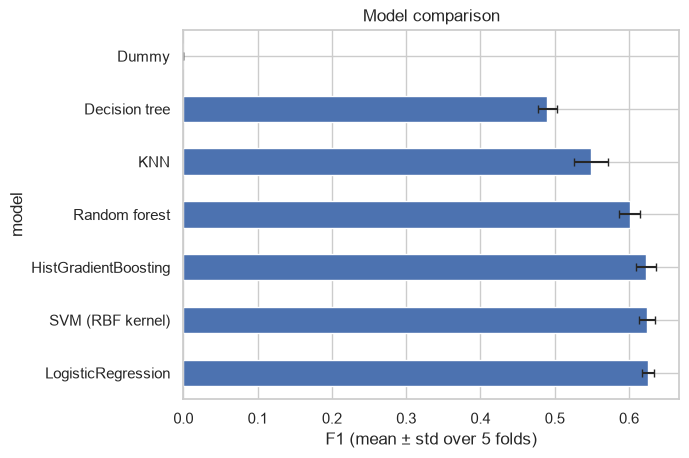

In [9]:
model_comparison_table["F1"].plot.barh(xerr=model_comparison_table["F1 std"], capsize=3)
plt.xlabel("F1 (mean ± std over 5 folds)")
plt.title("Model comparison")
plt.show()

All models beat the baseline. Logistic regression, SVM and HistGradientBoosting are tied on F1 (0.625, 0.624, 0.623, all within each other’s spread). Logistic regression has the best recall (0.801). Model to tune: logistic regression (best recall, simplest) and HistGradientBoosting (best tree model). SVM is not tuned because it is slow and offers no advantage.

---
## 6. Tune

A `GridSearchCV` or `RandomizedSearchCV` on the best one or two, on the training set. Report the best parameters and the cross-validated score.

In [10]:
pipe = Pipeline([("prep", preprocessor),
                 ("model", LogisticRegression())])

param_grid = [
    {"model": [LogisticRegression(max_iter=5000, class_weight="balanced")],
     "model__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    {"model": [HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)],
     "model__learning_rate": [0.03, 0.1, 0.3],
     "model__max_depth": [3, 5, None],
     "model__min_samples_leaf": [20, 50]},
]
search = GridSearchCV(pipe, param_grid, cv=CV, scoring=SCORING, refit="f2", n_jobs=-1)
search.fit(X_train, y_train)

def model_name(m):
    return type(m).__name__

def settings(params):
    return ", ".join(f"{k.split('__')[-1]}={v}" for k, v in params.items() if k != "model")

results = pd.DataFrame(search.cv_results_)
results["model"] = results["param_model"].map(model_name)
results["settings"] = results["params"].map(settings)
results[["model", "settings", "mean_test_f1", "std_test_f1", "mean_test_recall", "rank_test_f1"]] \
    .sort_values("rank_test_f1").head(10).round(3)

,model,settings,mean_test_f1,std_test_f1,mean_test_recall,rank_test_f1
15,HistGradientBoostingClassifier,"learning_rate=0.1, max_depth=5, min_samples_le...",0.638,0.010,0.784,1
10,HistGradientBoostingClassifier,"learning_rate=0.03, max_depth=None, min_sample...",0.636,0.010,0.780,2
9,HistGradientBoostingClassifier,"learning_rate=0.03, max_depth=5, min_samples_l...",0.633,0.007,0.793,3
12,HistGradientBoostingClassifier,"learning_rate=0.1, max_depth=3, min_samples_le...",0.633,0.014,0.801,4
8,HistGradientBoostingClassifier,"learning_rate=0.03, max_depth=5, min_samples_l...",0.632,0.012,0.786,5
13,HistGradientBoostingClassifier,"learning_rate=0.1, max_depth=3, min_samples_le...",0.631,0.013,0.799,6
11,HistGradientBoostingClassifier,"learning_rate=0.03, max_depth=None, min_sample...",0.630,0.011,0.779,7
14,HistGradientBoostingClassifier,"learning_rate=0.1, max_depth=5, min_samples_le...",0.630,0.012,0.763,8
7,HistGradientBoostingClassifier,"learning_rate=0.03, max_depth=3, min_samples_l...",0.629,0.010,0.807,9
6,HistGradientBoostingClassifier,"learning_rate=0.03, max_depth=3, min_samples_l...",0.629,0.010,0.807,10


In [11]:
lr_results = results[results["model"] == "LogisticRegression"].sort_values("rank_test_f1")
display(lr_results[["settings", "mean_test_f1", "std_test_f1", "mean_test_recall"]].head(1).round(3))

best_C = lr_results.iloc[0]["param_model__C"]
best_model = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(C=best_C, max_iter=5000, class_weight="balanced")),
])
best_model.fit(X_train, y_train)
print("Best C:", best_C)

,settings,mean_test_f1,std_test_f1,mean_test_recall
2,C=0.1,0.628,0.008,0.803


Best C: 0.1


In [12]:
print("Best settings:", search.best_params_)
print(f"Best cross-validated F1: {search.best_score_:.3f}")
best_hbg_model = search.best_estimator_    

Best settings: {'model': HistGradientBoostingClassifier(class_weight='balanced', random_state=0), 'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__min_samples_leaf': 50}
Best cross-validated F1: 0.725


Tuning improved F1 score by about 0.015. The best setting is `HistGradientBoosting` with `learning_rate = 0.1`, `model__max_depth: 5`, `model__min_samples_leaf: 50` at F1 0.638. The top 8 configurations are within 0.008 of each other, so the result isn’t sensitive to the exact settings. The Logistic regression C=0.1 scores 0.628 which lower than any of the tuned hgb.

---
## 7. Threshold

Classification only. Cross-validated probabilities on the training set with `cross_val_predict`, then the threshold that fits your metric and the cost of each mistake. Regression: delete this section and say why in the README.

In [13]:
proba_cv = cross_val_predict(best_model, X_train, y_train, cv=CV, method='predict_proba')[:, 1]

rows =[]
for threshold in np.arange(0.20, 0.80, 0.05): 
    pred = (proba_cv >= threshold).astype(int)
    rows.append({
        "threshold": threshold,
        "recall": recall_score(y_train, pred),
        "precision": precision_score(y_train, pred),
        "f1": f1_score(y_train, pred),
        "flagged_%": pred.mean() * 100,
        "missed churners": int(((pred == 0) & (y_train == 1)).sum()),
        "false alarms": int(((pred == 1) & (y_train == 0)).sum())
        })
thresholds = pd.DataFrame(rows)
thresholds.round(3)

,threshold,recall,precision,f1,flagged_%,missed churners,false alarms
0,0.20,0.955,0.379,0.543,66.897,67,2341
1,0.25,0.941,0.399,0.560,62.620,88,2121
2,0.30,0.926,0.421,0.579,58.360,110,1903
3,0.35,0.901,0.440,0.591,54.331,148,1714
4,0.40,0.865,0.466,0.606,49.255,202,1482
5,0.45,0.829,0.489,0.615,45.048,255,1298
6,0.50,0.803,0.516,0.628,41.321,294,1127
7,0.55,0.757,0.539,0.630,37.256,363,967
8,0.60,0.706,0.562,0.626,33.369,439,824
9,0.65,0.654,0.595,0.623,29.162,517,665


In [14]:
best = TunedThresholdClassifierCV(
    best_model,
    scoring=make_scorer(fbeta_score, beta=2),
    cv=CV,
    store_cv_results=True,
)
best.fit(X_train, y_train)

print(f"Best threshold: {best.best_threshold_:.3f}")
print(f"Best F2: {best.best_score_:.3f}")

Best threshold: 0.319
Best F2: 0.751


In [15]:
f2 = make_scorer(fbeta_score, beta=2)

final_candidates = {
    "LogisticRegression (C=0.1)": best_model,
    "HistGradientBoosting (tuned)": best_hbg_model,
}

rows = []
for name, model in final_candidates.items():
    tuned = TunedThresholdClassifierCV(model, scoring=f2, cv=CV)
    res = cross_validate(
        tuned, X_train, y_train, cv=CV,
        scoring={
            "f2": f2,
            "recall": "recall",
            "precision": make_scorer(precision_score, zero_division=0),
        },
        return_estimator=True,
        n_jobs=-1,
    )
    thresholds = [est.best_threshold_ for est in res["estimator"]]
    rows.append({
        "model": name,
        "F2": res["test_f2"].mean(),
        "F2 std": res["test_f2"].std(),
        "recall": res["test_recall"].mean(),
        "precision": res["test_precision"].mean(),
        "threshold (mean)": np.mean(thresholds),
    })

tuned_comparison = pd.DataFrame(rows).set_index("model").round(3)
tuned_comparison

,F2,F2 std,recall,precision,threshold (mean)
model,,,,,
LogisticRegression (C=0.1),0.749,0.005,0.917,0.433,0.325
HistGradientBoosting (tuned),0.742,0.009,0.915,0.424,0.336


### Final comparison at tuned thresholds

Both finalists were wrapped in `TunedThresholdClassifierCV` (F2) and evaluated with nested cross-validation: the outer 5 folds score the model, and the threshold is chosen inside each fold on training data only. Both were tuned with `refit="f2"`.

| Model | F2 | F2 std | Recall | Precision | Threshold |
|---|---|---|---|---|---|
| Logistic regression (C=0.1) | 0.749 | 0.005 | 0.917 | 0.433 | 0.325 |
| HistGradientBoosting (tuned) | 0.742 | 0.009 | 0.915 | 0.424 | 0.336 |

- At their own tuned thresholds the two models perform almost identically: the F2 gap (0.007) is smaller than the spread across folds, so neither is better than the other.
- They catch the same share of churners (recall ≈ 0.92) at similar precision (≈ 0.43 vs 0.42) and with nearly the same threshold (≈ 0.33).
- Logistic regression is slightly more stable across folds (F2 std 0.005 vs 0.009).
- Both clearly beat the always-"Yes" baseline (F2 ≈ 0.64).

**Final model: logistic regression** (`C=0.1`, `class_weight="balanced"`) with a threshold of about **0.32**, chosen by F2. Since the two models are tied, the simpler one is preferred: it is more stable, faster to train, and its coefficients show which customer traits raise churn risk, which the retention team can act on. At this threshold it catches about 92% of churners at a precision of about 43%, meaning that roughly 2 in 5 contacted customers would actually have churned.

---
## 8. The final model

Which model, which parameters, which threshold, and why. If a simpler model is within the noise of the best one, say which you chose and why.

In [17]:
import joblib
MODELS.mkdir(exist_ok=True)
joblib.dump({"model": best, "threshold": best.best_threshold_}, MODELS / "final_model.joblib")

['/Users/jkrstevska/Desktop/DSML/Week 6/project-2-ml/models/final_model.joblib']

## Final model: Logistic Regression
`C=0.1`, `class_weight="balanced"` wrapped in `TunedThresholdClassifierCV` with a threshold of **0.32**, chosen by F2.

After tuning, HistGradientBoosting had the best cross-validated F1 0.638, against 0.628 for logistic regression. The gap is about one standard deviation, so the two models are within the noise of each other. Logistic regression is the final model because it is much simpler, has the higher recall (0.803 vs 0.784 at the default threshold), and is easy to explain: its coefficients show which customer traits raise churn risk, which a retention team can act on.

Threshold: missing a churner costs more than an unnecessary offer, so the threshold favours recall. At 0.32 the model catches about 92% of churners, at the cost of more false alarms.

---
## Image option

If you chose the flower photos, sections 2 to 7 become: rescaling and augmentation layers; a CNN from scratch trained with early stopping, with its training curves; a frozen pretrained network (for example `MobileNetV2`) with a new output layer, trained the same way; and the two compared on the validation set. Fine-tuning the top of the pretrained network is optional.